In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn import metrics
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

import os


In [13]:
col_names =["pregnant","glucose","bp","skin","insulin","bmi","pedigre","age","label"]
pima = pd.read_csv("diabetes.csv", header=None, names= col_names)
df = pima.iloc[1:,:]
df

,pregnant,glucose,bp,skin,insulin,bmi,pedigre,age,label
1,6,148,72,35,0,33.6,0.627,50,1
2,1,85,66,29,0,26.6,0.351,31,0
3,8,183,64,0,0,23.3,0.672,32,1
4,1,89,66,23,94,28.1,0.167,21,0
5,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
764,10,101,76,48,180,32.9,0.171,63,0
765,2,122,70,27,0,36.8,0.34,27,0
766,5,121,72,23,112,26.2,0.245,30,0
767,1,126,60,0,0,30.1,0.349,47,1


In [14]:
#Selección de las características
feature_cols =["pregnant","insulin","bmi","age","glucose","bp","pedigre"]
X = df[feature_cols]
y = df.label

In [15]:
X_train, X_test, y_train, y_test =train_test_split(X,y,test_size = 0.2,random_state =1)

In [16]:
#sag: Stochastic Average Gradient
#newton-cg: Library for large linear classification (Algoritmo Coordinante Descent)
#saga: Variante del método sag
#lbfgs: Limited-memory Broyned_Fletcher_Goldfarb_Shanno Algoritm


# Regresión logística con Solucionador (Solver): sag

In [18]:
model= LogisticRegression(solver ="sag")
clf = model.fit(X_train, y_train)

In [20]:
#Predicción de etiquetas de clase sobre datos de prueba
y_pred = model.predict (X_test)

#Impresión de coeficientes de la regresión de puntajes
print ("Intercepto (Beta 0)", clf.intercept_)
print("Pesos de cada variable /Beta1,Beta2,...,Beta7)", clf.coef_)


Intercepto (Beta 0) [-0.01188571]
Pesos de cada variable /Beta1,Beta2,...,Beta7) [[ 0.05163491  0.00116592 -0.00938337 -0.00224372  0.01407241 -0.03084512
   0.00103528]]


In [21]:
#Evaluación de la presición del modelo
score = model.score(X_test,y_test)
print("Score de precisión:",score)

Score de precisión: 0.6428571428571429


In [23]:
#Reporte de clasificación
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.67      0.89      0.76        99
           1       0.50      0.20      0.29        55

    accuracy                           0.64       154
   macro avg       0.58      0.54      0.52       154
weighted avg       0.61      0.64      0.59       154



# Regresión logística con Solucionador (Solver): newton-cg

In [30]:
model = LogisticRegression(solver="newton-cg")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercepto (Beta0):",clf.intercept_)
print("Pesos (Betas):",clf.coef_)
print("-----------------------------------------------------------")
score=model.score(X_test, y_test)
print("Precición global:", score)
print("-----------------------------------------------------------")
print(classification_report(y_test,y_pred))

Intercepto (Beta0): [-8.09000764]
Pesos (Betas): [[ 0.12708883 -0.00095862  0.08544419  0.01165675  0.03653129 -0.01510559
   0.63044762]]
-----------------------------------------------------------
Precición global: 0.7727272727272727
-----------------------------------------------------------
              precision    recall  f1-score   support

           0       0.78      0.90      0.84        99
           1       0.75      0.55      0.63        55

    accuracy                           0.77       154
   macro avg       0.77      0.72      0.73       154
weighted avg       0.77      0.77      0.76       154



# Regresión logística con Solucionador (Solver): liblinear

In [31]:
model = LogisticRegression(solver="liblinear")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercepto (Beta0):",clf.intercept_)
print("Pesos (Betas):",clf.coef_)
print("-----------------------------------------------------------")
score=model.score(X_test, y_test)
print("Precición global:", score)
print("-----------------------------------------------------------")
print(classification_report(y_test,y_pred))

Intercepto (Beta0): [-5.38033815]
Pesos (Betas): [[ 1.18843413e-01 -3.17269639e-04  5.28290919e-02  3.80596808e-03
   2.87936243e-02 -1.90988005e-02  4.74903576e-01]]
-----------------------------------------------------------
Precición global: 0.7662337662337663
-----------------------------------------------------------
              precision    recall  f1-score   support

           0       0.77      0.90      0.83        99
           1       0.74      0.53      0.62        55

    accuracy                           0.77       154
   macro avg       0.76      0.71      0.72       154
weighted avg       0.76      0.77      0.76       154



# Regresión logística con Solucionador (Solver): saga

In [32]:
model = LogisticRegression(solver="saga")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercepto (Beta0):",clf.intercept_)
print("Pesos (Betas):",clf.coef_)
print("-----------------------------------------------------------")
score=model.score(X_test, y_test)
print("Precición global:", score)
print("-----------------------------------------------------------")
print(classification_report(y_test,y_pred))

Intercepto (Beta0): [-0.0061133]
Pesos (Betas): [[ 0.03009594  0.00115533 -0.00945605  0.00096017  0.01388583 -0.03084108
   0.00049922]]
-----------------------------------------------------------
Precición global: 0.6493506493506493
-----------------------------------------------------------
              precision    recall  f1-score   support

           0       0.67      0.89      0.77        99
           1       0.52      0.22      0.31        55

    accuracy                           0.65       154
   macro avg       0.60      0.55      0.54       154
weighted avg       0.62      0.65      0.60       154



# Regresión logística con Solucionador (Solver): lbfgs

In [33]:
model = LogisticRegression(solver="lbfgs")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercepto (Beta0):",clf.intercept_)
print("Pesos (Betas):",clf.coef_)
print("-----------------------------------------------------------")
score=model.score(X_test, y_test)
print("Precición global:", score)
print("-----------------------------------------------------------")
print(classification_report(y_test,y_pred))

Intercepto (Beta0): [-8.10385689]
Pesos (Betas): [[ 0.12715717 -0.00096267  0.08559411  0.01168201  0.03657089 -0.01508644
   0.63352715]]
-----------------------------------------------------------
Precición global: 0.7727272727272727
-----------------------------------------------------------
              precision    recall  f1-score   support

           0       0.78      0.90      0.84        99
           1       0.75      0.55      0.63        55

    accuracy                           0.77       154
   macro avg       0.77      0.72      0.73       154
weighted avg       0.77      0.77      0.76       154



In [35]:
# Predicción de probabilidades para casos particuleres
y_pred_probs = clf.predict_proba(X_test)[:,1]
y_pred_probs[0:5]

array([0.43650671, 0.31967419, 0.15787838, 0.04340139, 0.19968362])

In [36]:
y_test[0:5]

286    0
102    0
582    0
353    0
727    0
Name: label, dtype: object

In [37]:
y_test = y_test.to_numpy()
y_test[0:5]

array(['0', '0', '0', '0', '0'], dtype=object)

In [39]:
y_test = [int(numeric_string) for numeric_string in y_test]
y_test[0:5]


[0, 0, 0, 0, 0]

In [40]:
import numpy as np
y_pred_probs = np.round(y_pred_probs,0)
y_pred_probs[0:5]

array([0., 0., 0., 0., 0.])

In [42]:
#Graficación de la curva ROC y cálculo del área bajo ella
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

#fpr =false positive rate
#tpr = true positive rate
#threshols = limites para valores de p

fpr,tpr, thresholds = roc_curve(y_test,y_pred_probs)
auc = roc_auc_score(y_test, y_pred_probs)

Text(0.5, 1.0, 'Curva ROC para Regresión Logística')

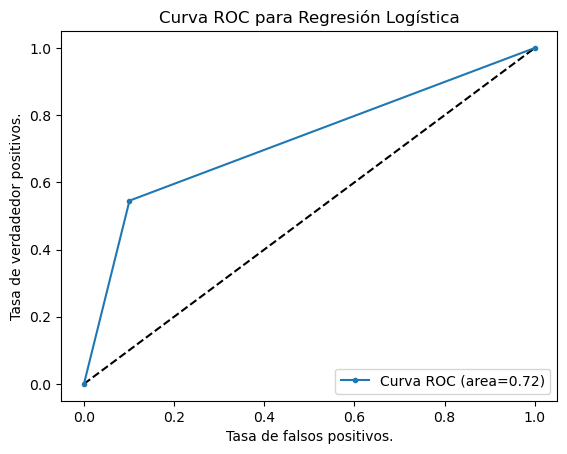

In [43]:
plt.plot([0,1],[0,1], 'k--')
plt.plot (fpr,tpr,marker=".",label = "Curva ROC (área=%0.2f)" % auc)
plt.xlabel("Tasa de falsos positivos.")
plt.ylabel("Tasa de verdadedor positivos.")
plt.legend(loc= "lower right")
plt.title("Curva ROC para Regresión Logística")